In [4]:
import sys
print(sys.executable)

c:\Users\nonay\AppData\Local\Programs\Python\Python311\python.exe


In [1]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("Python:", tf.__version__)

TensorFlow Version: 2.21.0
Python: 2.21.0


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [3]:
train_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\train"

val_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\validation"

test_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\test"

In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [5]:
train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

validation_dataset = image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

Found 15442 files belonging to 3 classes.
Found 1930 files belonging to 3 classes.
Found 1932 files belonging to 3 classes.


In [6]:
print(train_dataset.class_names)

['diabetic_retinopathy', 'glaucoma', 'normal']


In [7]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

In [8]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

labels = []

for images, y in train_dataset:
    labels.extend(np.argmax(y.numpy(), axis=1))

labels = np.array(labels)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(0.6356301967564008), 1: np.float64(1.3499431768511234), 2: np.float64(1.4577551213065232)}


In [9]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [10]:
inputs = tf.keras.Input(shape=(224,224,3))

x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.3)(x)

outputs = Dense(3, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

In [11]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "efficientnet_stage1.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

In [15]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint]
)

d:\DR AND GLAUCOMA DETECTION PROJECT\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8295 - loss: 0.3857
Epoch 1: val_accuracy improved from None to 0.83212, saving model to efficientnet_stage1.keras

Epoch 1: finished saving model to efficientnet_stage1.keras
483/483 ━━━━━━━━━━━━━━━━━━━━ 682s 1s/step - accuracy: 0.8295 - loss: 0.3857 - val_accuracy: 0.8321 - val_loss: 0.3751
Epoch 2/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8727 - loss: 0.2601
Epoch 2: val_accuracy improved from 0.83212 to 0.84922, saving model to efficientnet_stage1.keras

Epoch 2: finished saving model to efficientnet_stage1.keras
483/483 ━━━━━━━━━━━━━━━━━━━━ 666s 1s/step - accuracy: 0.8727 - loss: 0.2601 - val_accuracy: 0.8492 - val_loss: 0.3256
Epoch 3/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8825 - loss: 0.2349
Epoch 3: val_accuracy improved from 0.84922 to 0.87668, saving model to efficientnet_stage1.keras

Epoch 3: finished saving model to efficientnet_stage1.keras
483/483 ━━━━━━━━━━━━━━━━━━━━ 631s 1

In [18]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

61/61 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.8944 - loss: 0.2251
Test Loss: 0.22509509325027466
Test Accuracy: 0.8944099545478821


In [19]:
model.save("efficientnet_stage1_final.keras")

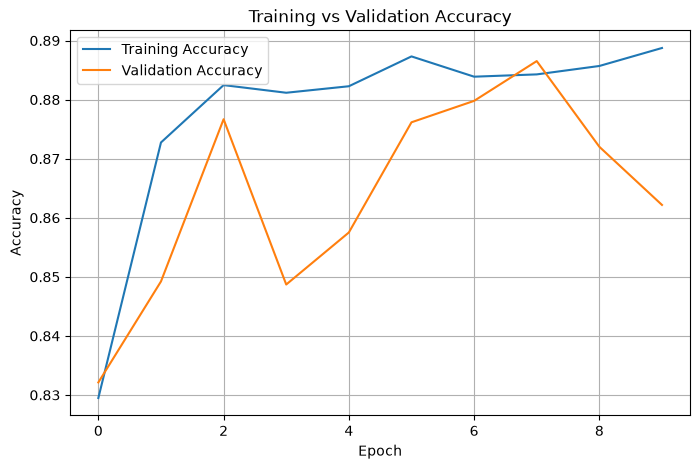

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

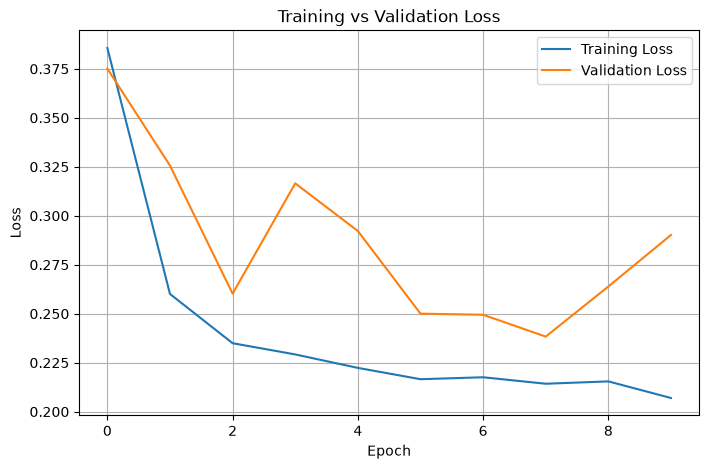

In [21]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
from sklearn.metrics import classification_report
import numpy as np

predictions = model.predict(test_dataset)
predicted_labels = np.argmax(predictions, axis=1)

true_labels = []
for images, labels in test_dataset:
    true_labels.extend(np.argmax(labels.numpy(), axis=1))

true_labels = np.array(true_labels)

print(classification_report(
    true_labels,
    predicted_labels,
    target_names=train_dataset.class_names
))

61/61 ━━━━━━━━━━━━━━━━━━━━ 67s 977ms/step
                      precision    recall  f1-score   support

diabetic_retinopathy       0.97      0.84      0.90      1013
            glaucoma       0.96      1.00      0.98       477
              normal       0.72      0.92      0.81       442

            accuracy                           0.89      1932
           macro avg       0.88      0.92      0.89      1932
        weighted avg       0.91      0.89      0.90      1932



In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(true_labels, predicted_labels)

print(cm)

[[846  10 157]
 [  0 477   0]
 [ 25  12 405]]


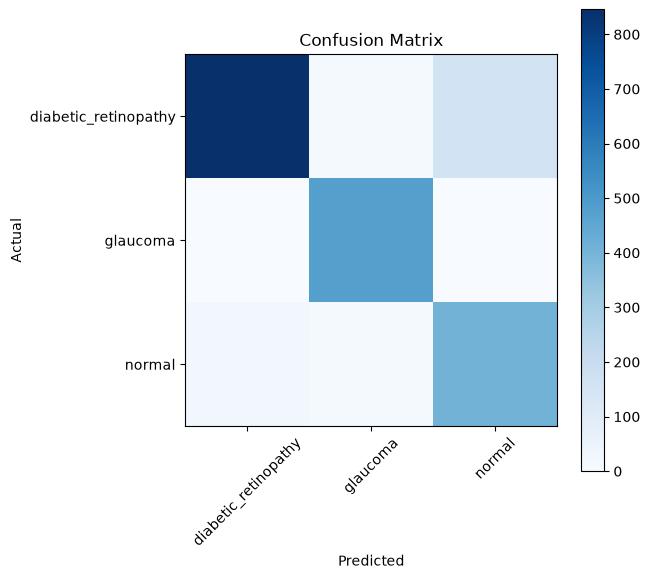

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(cm, cmap="Blues")

plt.xticks(range(3), train_dataset.class_names, rotation=45)
plt.yticks(range(3), train_dataset.class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.colorbar()

plt.show()

In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(true_labels, predicted_labels, average='weighted')
recall = recall_score(true_labels, predicted_labels, average='weighted')
f1 = f1_score(true_labels, predicted_labels, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Accuracy : 0.8944
Precision: 0.9102
Recall   : 0.8944
F1-Score : 0.8968


In [14]:
from tensorflow.keras.models import load_model

model = load_model(
    r"D:\DR AND GLAUCOMA DETECTION PROJECT\models\efficientnet_stage1_final.keras"
)

In [13]:
import os
print(os.getcwd())

d:\DR AND GLAUCOMA DETECTION PROJECT\models


In [15]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

61/61 ━━━━━━━━━━━━━━━━━━━━ 73s 971ms/step - accuracy: 0.8944 - loss: 0.2251
Test Loss: 0.22509509325027466
Test Accuracy: 0.8944099545478821


In [16]:
predictions = model.predict(test_dataset)

61/61 ━━━━━━━━━━━━━━━━━━━━ 63s 960ms/step


In [17]:
import numpy as np

y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_true = np.argmax(y_true, axis=1)

y_pred = np.argmax(predictions, axis=1)

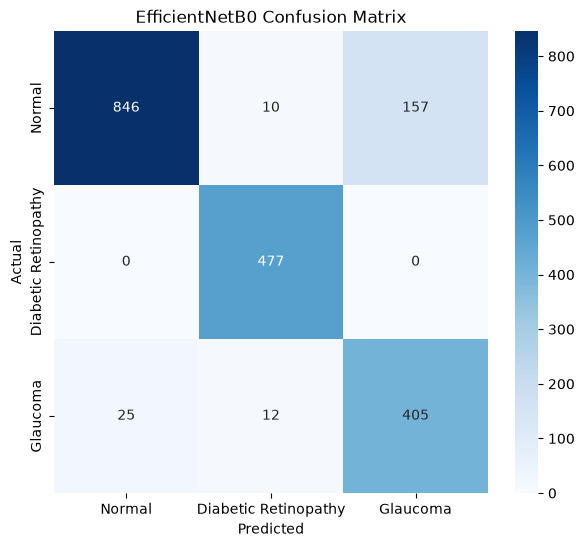

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Diabetic Retinopathy", "Glaucoma"],
    yticklabels=["Normal", "Diabetic Retinopathy", "Glaucoma"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNetB0 Confusion Matrix")
plt.show()